# DoE augmentation — recycle level as a design factor

The measurement plan handed off in August crosses every one of the 12 formulations with the whole
1× / 5× / 10× recycle series (36 samples, ~108 recycling loops). Question raised on 2026-09-17: can the recycle
level be treated as a **design factor** instead, so fewer samples are needed, **without discarding the 12
formulations already requested** (9 measured at 1×, 3 TPU pending)?

Both options below keep the requested runs fixed and **augment** them so that the union is space-filling over
(polymer, PAL %, temperature, recycle level):

* **Option A — reuse the requested formulations.** Candidates are the 12 formulations at 5× / 10×; an exchange
  search picks the best subset. No new compounding; some formulations get a 1× → 5× → 10× trajectory.
* **Option B — augmented Latin hypercube (new formulations).** The new runs are an LHS over
  polymer × PAL × temperature × recycle (5–10×), placed in the strata the existing runs leave free, and optimised
  by **column permutations** (which keep the Latin structure) against the union. New formulations to compound;
  best coverage of the factor space.

Logic in `utils/doe.py` (`augment_plan`, `augment_lhs`, `plan_metrics`), figure in `utils/plots.py`.
**Nothing is written by default** — each cell that can save has a `SAVE_*` switch and a name.

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "utils").exists() and (ROOT.parent / "utils").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from utils import config, io, instron, doe, plots

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
plt.rcParams["figure.dpi"] = 110
p = config.paths(ROOT)

---
## 1 — What is fixed: the requested formulations at 1×

The 12 formulations of `doe/doe_formulations.csv`. Nine have tensile data (2026-09-03 delivery, assumed 1×);
f05 / f07 / f11 (TPU) are still owed by the lab and stay in the plan as requested runs.

In [2]:
design = pd.read_csv(p.doe / "doe_formulations.csv")
plan_full = doe.expand_recycle(design)                                  # the 36-sample plan as handed off
cat = instron.catalogue(io.extract_zip(p.raw_doe))                       # what has been delivered so far
existing = design.assign(recycle_level=1)
existing["measured"] = existing["formulation"].isin(cat["formulation"]).map({True: "yes", False: "pending"})
print(f"{len(existing)} requested runs at 1x: {(existing['measured'] == 'yes').sum()} measured, "
      f"{(existing['measured'] == 'pending').sum()} pending  ·  full plan: {len(plan_full)} samples, "
      f"{doe.plan_metrics(plan_full)['loops']} recycling loops")
existing

12 requested runs at 1x: 9 measured, 3 pending  ·  full plan: 36 samples, 108 recycling loops


,formulation,polymer_system,PAL_pct,extrusion_temp_C,recycle_level,measured
0,1,HDPE+PAL,49,220,1,yes
1,2,HDPE+PAL,23,235,1,yes
2,3,PP+PAL,15,225,1,yes
3,4,PP+PAL,28,180,1,yes
4,5,TPU+PAL,37,230,1,pending
5,6,PP+PAL,41,205,1,yes
6,7,TPU+PAL,11,200,1,pending
7,8,TPU+PAL,46,185,1,yes
8,9,HDPE+PAL,35,200,1,yes
9,10,HDPE+PAL,19,195,1,yes


---
## 2 — Objective and cost, common to both options

**Objective** (minimised over the union of requested + proposed runs, coded to the unit cube):
`centered discrepancy (pooled)` + `mean centered discrepancy within each polymer` + `0.1 × max |factor correlation|`.
Discrepancy is the criterion the original LHS was optimised on; the per-polymer term keeps each polymer
space-filling on its own; the correlation term stops the recycle level from lining up with PAL % or temperature.

**Cost:** `loops` = recycling loops beyond the first extrusion, summed over formulations (a formulation taken to
10× needs 9, and passes through 5× on the way); `formulations` = batches to compound.

### Option A — requested formulations at 5× / 10×, exchange search

{'n_runs': 24, 'cd_pooled': 0.074, 'cd_slices': 0.104, 'phi_pooled': 6.262, 'max_abs_corr': 0.023, 'loops': 70, 'objective': 0.18}
per level: {5: 6, 10: 6} · formulations touched: [1, 2, 3, 4, 5, 6, 7, 9, 10, 11]


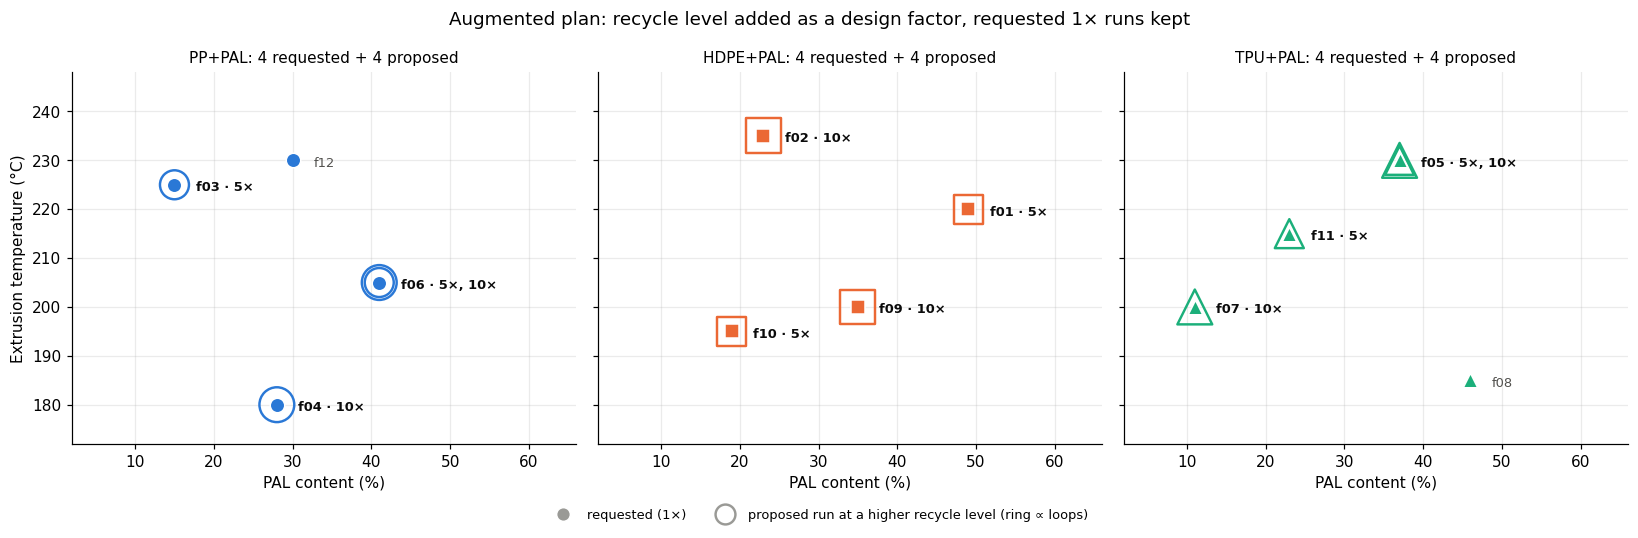

In [3]:
N_NEW_A = 12               # proposed runs to add (balanced across polymers)
LEVELS_A = (5, 10)         # recycle levels a proposed run may use
SAVE_FIG = False                      # True -> write the figure to processed_data/figures/
FIG_NAME = "doe_augmented_plan_A"

plan_A, new_A, q_A = doe.augment_plan(design, N_NEW_A, levels=LEVELS_A)
print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in q_A.items()})
print(f"per level: {new_A['recycle_level'].value_counts().sort_index().to_dict()} · "
      f"formulations touched: {sorted(int(f) for f in new_A['formulation'].unique())}")
plots.doe_augmented(plan_A, save=io.save_path(p.figures, FIG_NAME, SAVE_FIG, ".png"))

### Option B — augmented LHS with new formulations, permutation search

PAL % and temperature are split into 12 + 12 = 24 strata; the 12 new formulations take the 12 strata the requested
ones leave free, so the **union is a 24-run Latin hypercube** in those two factors (before rounding to the 1 % /
5 °C grid the lab can set). The recycle level gets 12 Latin strata over 5–10× (whole loops); set
`RECYCLE_LEVELS = (5, 10)` instead to allow only the two agreed levels. The search swaps the values of two runs in
one factor at a time — a column permutation, so every factor stays Latin — and keeps the swap when the objective of
the union improves.

{'n_runs': 24, 'cd_pooled': 0.054, 'cd_slices': 0.068, 'phi_pooled': 6.099, 'max_abs_corr': 0.005, 'loops': 78, 'objective': 0.123}
per level: {5: 1, 6: 3, 7: 2, 8: 2, 9: 3, 10: 1}


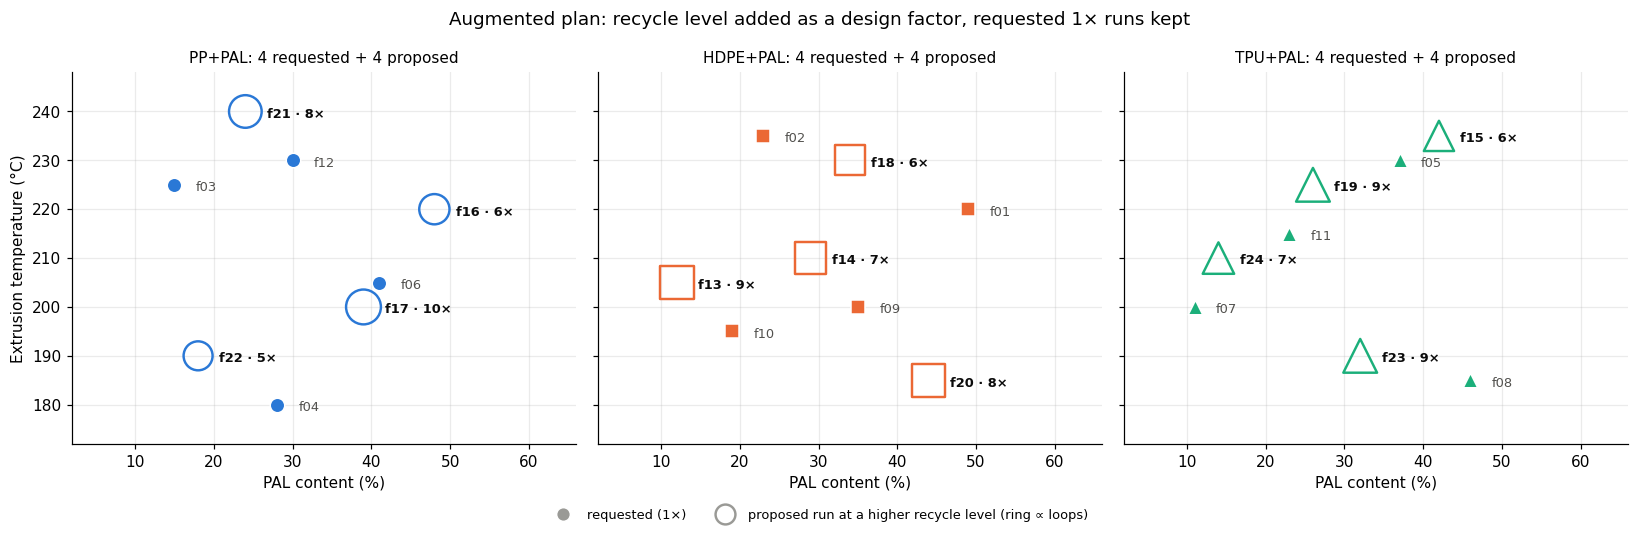

In [4]:
N_NEW_B = 12               # new formulations (balanced across polymers)
RECYCLE_RANGE = (5, 10)    # Latin strata over this range of loops ...
RECYCLE_LEVELS = None      # ... or a fixed set of levels, e.g. (5, 10)
SAVE_FIG = False                      # True -> write the figure to processed_data/figures/
FIG_NAME = "doe_augmented_plan_B"

plan_B, new_B, q_B = doe.augment_lhs(design, N_NEW_B, recycle_range=RECYCLE_RANGE, recycle_levels=RECYCLE_LEVELS)
print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in q_B.items()})
print(f"per level: {new_B['recycle_level'].value_counts().sort_index().to_dict()}")
plots.doe_augmented(plan_B, save=io.save_path(p.figures, FIG_NAME, SAVE_FIG, ".png"))

In [5]:
new_B[["formulation", "polymer_system", "PAL_pct", "extrusion_temp_C", "recycle_level"]]

,formulation,polymer_system,PAL_pct,extrusion_temp_C,recycle_level
0,13,HDPE+PAL,12,205,9
1,14,HDPE+PAL,29,210,7
2,15,TPU+PAL,42,235,6
3,16,PP+PAL,48,220,6
4,17,PP+PAL,39,200,10
5,18,HDPE+PAL,34,230,6
6,19,TPU+PAL,26,225,9
7,20,HDPE+PAL,44,185,8
8,21,PP+PAL,24,240,8
9,22,PP+PAL,18,190,5


### Options side by side
Lower discrepancy = more uniform coverage of the (PAL, temperature, recycle) cube; the requested 1× runs alone sit
on one plane, hence their poor value. Option B is run for the 5–10× range and for the two agreed levels only.

In [6]:
options = {"full cross (as handed off)": plan_full, "requested 1x only": existing.drop(columns="measured")}
for k in (6, 12, 18):
    options[f"A: +{k} runs, requested formulations at 5x/10x"] = doe.augment_plan(design, k)[0]
    options[f"B: +{k} new formulations, LHS over 5-10x"] = doe.augment_lhs(design, k)[0]
    options[f"B: +{k} new formulations, LHS at 5x/10x only"] = doe.augment_lhs(design, k, recycle_levels=(5, 10))[0]
compare = pd.DataFrame({name: doe.plan_metrics(pl) for name, pl in options.items()}).T
compare.insert(1, "formulations", [int(pl["formulation"].nunique()) for pl in options.values()])
compare["tensile specimens (3-5 reps)"] = [f"{3 * int(n)}-{5 * int(n)}" for n in compare["n_runs"]]
compare.drop(columns=["phi_pooled", "objective"]).round(3)

,n_runs,formulations,cd_pooled,cd_slices,max_abs_corr,loops,tensile specimens (3-5 reps)
full cross (as handed off),36.0,12,0.039,0.067,0.079,108.0,108-180
requested 1x only,12.0,12,0.401,0.438,0.079,0.0,36-60
"A: +6 runs, requested formulations at 5x/10x",18.0,12,0.138,0.178,0.077,49.0,54-90
"B: +6 new formulations, LHS over 5-10x",18.0,18,0.130,0.158,0.022,39.0,54-90
"B: +6 new formulations, LHS at 5x/10x only",18.0,18,0.143,0.167,0.013,39.0,54-90
"A: +12 runs, requested formulations at 5x/10x",24.0,12,0.074,0.104,0.023,70.0,72-120
"B: +12 new formulations, LHS over 5-10x",24.0,24,0.054,0.068,0.005,78.0,72-120
"B: +12 new formulations, LHS at 5x/10x only",24.0,24,0.070,0.082,0.011,78.0,72-120
"A: +18 runs, requested formulations at 5x/10x",30.0,12,0.049,0.078,0.009,88.0,90-150
"B: +18 new formulations, LHS over 5-10x",30.0,30,0.029,0.037,0.005,117.0,90-150


---
## 3 — Hand-off table

Same layout as `doe/doe_measurement_plan.xlsx`: one row per sample, `status` = requested (already in the plan /
measured) or proposed (new). Pick the option, then switch the save on.

In [7]:
CHOSEN = "B"                          # "A" or "B"
SAVE_XLSX = False                     # True -> write the augmented plan to doe/<XLSX_NAME>.xlsx
XLSX_NAME = "doe_measurement_plan_augmented"

plan, proposed, quality = {"A": (plan_A, new_A, q_A), "B": (plan_B, new_B, q_B)}[CHOSEN]
if SAVE_XLSX:
    with pd.ExcelWriter(io.save_path(p.doe, XLSX_NAME, ext=".xlsx"), engine="openpyxl") as xw:
        plan.to_excel(xw, sheet_name="plan", index=False)
        proposed.to_excel(xw, sheet_name="proposed_only", index=False)
        compare.round(4).to_excel(xw, sheet_name="options")
print(f"option {CHOSEN}: {len(plan)} samples = {int((plan['status'] == 'requested').sum())} requested + "
      f"{int((plan['status'] == 'proposed').sum())} proposed · {plan['formulation'].nunique()} formulations · "
      f"{quality['loops']} recycling loops (full cross: {doe.plan_metrics(plan_full)['loops']})")
plan[["run", "formulation", "polymer_system", "PAL_pct", "extrusion_temp_C", "recycle_level", "status"]]

option B: 24 samples = 12 requested + 12 proposed · 24 formulations · 78 recycling loops (full cross: 108)


,run,formulation,polymer_system,PAL_pct,extrusion_temp_C,recycle_level,status
0,1,1,HDPE+PAL,49,220,1,requested
1,2,2,HDPE+PAL,23,235,1,requested
2,3,3,PP+PAL,15,225,1,requested
3,4,4,PP+PAL,28,180,1,requested
4,5,5,TPU+PAL,37,230,1,requested
5,6,6,PP+PAL,41,205,1,requested
6,7,7,TPU+PAL,11,200,1,requested
7,8,8,TPU+PAL,46,185,1,requested
8,9,9,HDPE+PAL,35,200,1,requested
9,10,10,HDPE+PAL,19,195,1,requested


---
## Reading the result

* Both options leave the requested runs untouched and add samples on top of them.
* **Option B covers the factor space best** — at 24 samples its per-polymer discrepancy matches the 36-sample
  full cross — because the new points fill the PAL × temperature strata the first design left empty *and* spread
  over the recycle axis. It costs 12 new compoundings and slightly more loops than option A.
* **Option A costs no new compounding** and gives a few formulations a full 1× → 5× → 10× trajectory (the only
  comparison clean of formulation-to-formulation differences, which matters with batch-1 CVs up to 55 %), but its
  coverage is weaker: the same 12 (PAL, T) points, only lifted in recycle.
* In both, the degradation effect is estimated mostly *across* formulations, by the model; only the full cross
  measures it within every formulation.
* When runs are scarce the criterion favours the far end of the recycle axis (10×), which also matches the physics:
  10× carries the most degradation signal and 5× material is produced on the way.